In [1]:
#libraries
# TensorFlow, google machine learning library
import tensorflow as tf
# Neural networks library
from tensorflow import keras
# database management library
import pandas as pd
# linear algebra library
import numpy as np
# plot library
import matplotlib.pyplot as plt
# scientific math library
import scipy.io
# machine learning library
import sklearn as skl
from sklearn import preprocessing
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold 
from sklearn.model_selection import GridSearchCV
from sklearn import preprocessing
from sklearn.decomposition import PCA
# pseudo-random numbers library
import random
# library for correlation map
import seaborn as sns
#
import matplotlib.pyplot as plt
#
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsRegressor
# results cache
import os, glob, shutil
import joblib

# Introduction - Inverter dataset

The dataset is described in the paper "Data Set Description: Three-Phase IGBT Two-Level Inverter for Electrical Drives" by Stender et al. 
and it is available at the link: https://www.kaggle.com/stender/inverter-data-set

The data set comprises several sensor data collected from a typical combined system between an inverter, an induction motor, and a control system, deployed on a test bench. Test bench measurements were collected by the LEA department at Paderborn University.

The dataset includes the following variables:

 1.   n_k                                    motor rotational speed [rpm]
 2.   u_dc_k,k-1,k-2,k-3                     Inverter DC voltage at time k, k-1, k-2, k-3 [V]   
 3.   i_x_k,k-1,k-2,k-3 x=phase A, B C       Inverter AC phase current at time k, k-1, k-2, k-3 [A]   
 4.   d_x_k-2,k-3 x=phase A, B C             Inverter PWM duty cycle at time k-2, k-3 [0-1]   
 5.   u_x_k-1 x=phase A, B C                 Inverter phase voltage at time k-1 [V]   

Our goal is to use motor speed, inverter DC voltages, inverter phase currents and duty cycle as input data in order to predict inverter phase voltages. We model phase A only, since phases B and C are symmetric.
The target is a mean absolute error (MAE) below 2 V.
This would reproduce an inverter black-box model that could be very useful to simulate an eDrive system and to create an ad hoc inverter control without using voltage sensors on each AC phase.

Since we are dealing with a sampled analog value the methods that we are going to use will be regression algorithms.
In particular, we have identified as suitable the following methods:

1. Decision Tree
2. Pruning
3. Random Forest
4. k-nearest neighbors
5. Artificial neural network

These methods are compared with simple references based on the physics of the inverter.

We have considered also to apply data selection methods in order to see what is the effect on the results by using a smaller amount of inputs.
The regression algorithm will be compared by employing the following dataset:

- all the variables
- Analysis PCA 

To finalize the analysis, a sensitivity study on hyperparameters will be carried out for model accuracy improvements.
 

In [2]:
#We fix the random seed in order to allow repeatability
random.seed(10)
np.random.seed(10)
tf.random.set_seed(10)

In [3]:
#Import dataset
data_raw=pd.read_csv('../input/inverter-data-set/Inverter Data Set.csv')
data_raw.head(10)


,n_k,u_dc_k,u_dc_k-1,u_dc_k-2,u_dc_k-3,i_a_k,i_b_k,i_c_k,i_a_k-1,i_b_k-1,...,i_c_k-3,d_a_k-2,d_b_k-2,d_c_k-2,d_a_k-3,d_b_k-3,d_c_k-3,u_a_k-1,u_b_k-1,u_c_k-1
0,3001.406296,567.985297,567.689956,567.431534,567.948379,2.461991,-1.792057,-0.716639,2.729208,-2.098439,...,-0.613965,0.667181,0.874633,0.125367,0.706206,0.862754,0.137246,360.541201,510.640963,82.471117
1,3001.468250,567.911462,567.985297,567.689956,567.431534,2.292110,-1.556948,-0.757338,2.461991,-1.792057,...,-0.758263,0.642184,0.880046,0.119954,0.667181,0.874633,0.125367,346.410081,513.190083,79.729357
2,3001.527815,567.911462,567.911462,567.985297,567.689956,2.155288,-1.332946,-0.840587,2.292110,-1.556948,...,-0.698139,0.611911,0.884307,0.115693,0.642184,0.880046,0.119954,329.440240,515.804643,77.924637
3,3001.585080,567.653039,567.911462,567.911462,567.985297,2.048768,-1.135788,-0.925686,2.155288,-1.332946,...,-0.716639,0.578149,0.888915,0.111085,0.611911,0.884307,0.115693,311.058880,517.537603,75.478717
4,3001.640131,567.579204,567.653039,567.911462,567.911462,1.952350,-0.918266,-1.027434,2.048768,-1.135788,...,-0.757338,0.541979,0.892123,0.107877,0.578149,0.888915,0.111085,290.481760,519.138403,73.580077
5,3001.693049,567.579204,567.579204,567.653039,567.911462,1.863278,-0.710000,-1.137507,1.952350,-0.918266,...,-0.840587,0.504439,0.894707,0.105293,0.541979,0.892123,0.107877,268.514480,519.268483,72.567117
6,3001.752952,567.689956,567.579204,567.579204,567.653039,1.767777,-0.498957,-1.276255,1.863278,-0.710000,...,-0.925686,0.465802,0.895410,0.104590,0.504439,0.894707,0.105293,247.132399,518.989763,72.276637
7,3001.873562,567.505369,567.689956,567.579204,567.579204,1.690643,-0.261997,-1.414078,1.767777,-0.498957,...,-1.027434,0.426395,0.894788,0.105212,0.465802,0.895410,0.104590,224.485519,517.429603,73.144157
8,3001.996791,567.653039,567.505369,567.689956,567.579204,1.613508,-0.060210,-1.554676,1.690643,-0.261997,...,-1.137507,0.386276,0.892363,0.107637,0.426395,0.894788,0.105212,202.544479,512.005363,74.859917
9,3002.113320,567.874544,567.653039,567.505369,567.689956,1.545556,0.116585,-1.677699,1.613508,-0.060210,...,-1.276255,0.345641,0.888466,0.111534,0.386276,0.892363,0.107637,179.174158,503.316483,77.297437


In [4]:
#describes the variables present in the dataset
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234527 entries, 0 to 234526
Data columns (total 26 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   n_k       234527 non-null  float64
 1   u_dc_k    234527 non-null  float64
 2   u_dc_k-1  234527 non-null  float64
 3   u_dc_k-2  234527 non-null  float64
 4   u_dc_k-3  234527 non-null  float64
 5   i_a_k     234527 non-null  float64
 6   i_b_k     234527 non-null  float64
 7   i_c_k     234527 non-null  float64
 8   i_a_k-1   234527 non-null  float64
 9   i_b_k-1   234527 non-null  float64
 10  i_c_k-1   234527 non-null  float64
 11  i_a_k-2   234527 non-null  float64
 12  i_b_k-2   234527 non-null  float64
 13  i_c_k-2   234527 non-null  float64
 14  i_a_k-3   234527 non-null  float64
 15  i_b_k-3   234527 non-null  float64
 16  i_c_k-3   234527 non-null  float64
 17  d_a_k-2   234527 non-null  float64
 18  d_b_k-2   234527 non-null  float64
 19  d_c_k-2   234527 non-null  float64
 20  d_a_

Histograms have been drawn in order to see if all the variables fall in a physical reliable range.

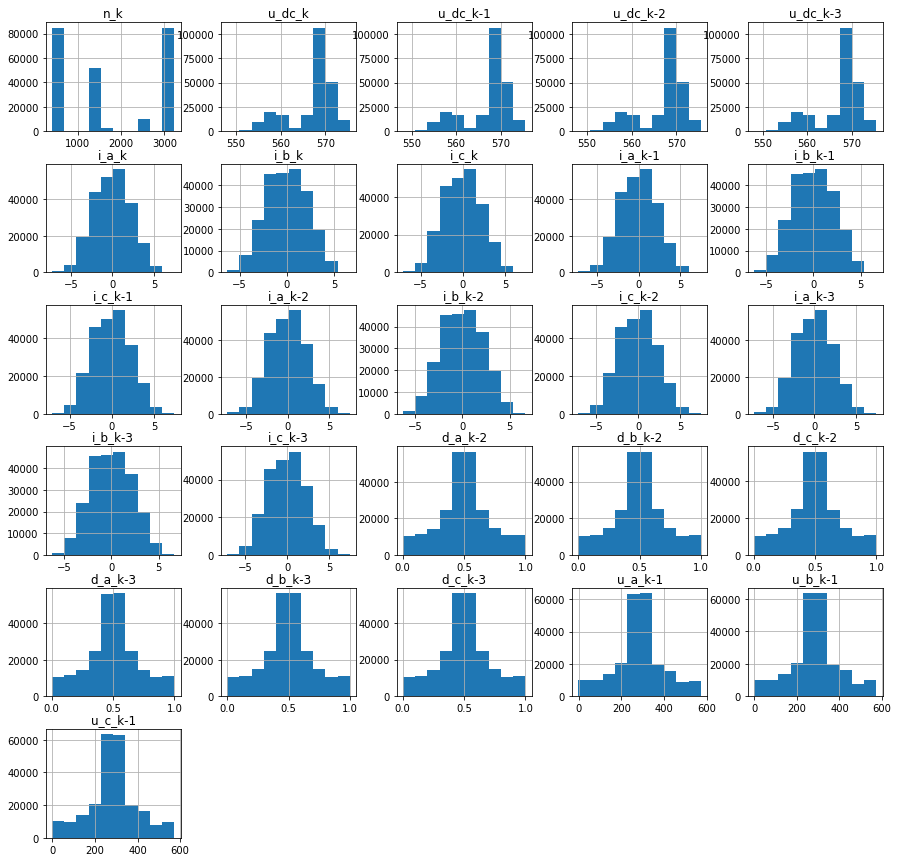

In [5]:
data_raw.hist(figsize=(15,15));

In [6]:
#describes the main features of our data
data_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
n_k,234527.0,1728.414990,1084.463934,404.433935,507.572918,1501.516456,2996.851500,3231.756077
u_dc_k,234527.0,567.136398,4.993615,548.012908,566.730100,568.649812,570.126514,575.553392
u_dc_k-1,234527.0,567.136565,4.993462,548.012908,566.730100,568.649812,570.126514,575.553392
u_dc_k-2,234527.0,567.136718,4.993317,548.012908,566.730100,568.649812,570.126514,575.553392
u_dc_k-3,234527.0,567.136882,4.993180,548.012908,566.730100,568.649812,570.126514,575.553392
i_a_k,234527.0,0.000505,2.199349,-7.300153,-1.573353,0.023062,1.552902,7.470243
i_b_k,234527.0,-0.007692,2.155399,-6.320221,-1.576386,0.000881,1.557785,6.668168
i_c_k,234527.0,-0.008975,2.216263,-7.112914,-1.591675,0.010400,1.566225,7.437108
i_a_k-1,234527.0,0.000518,2.199206,-7.300153,-1.572894,0.023062,1.552902,7.470243
i_b_k-1,234527.0,-0.007737,2.155302,-6.320221,-1.576386,0.000881,1.557785,6.668168


In [7]:
#check if there are null values
data_raw.isnull().values.any()

False

Some plots have been done in order to visualize the quantities with which we are dealing.

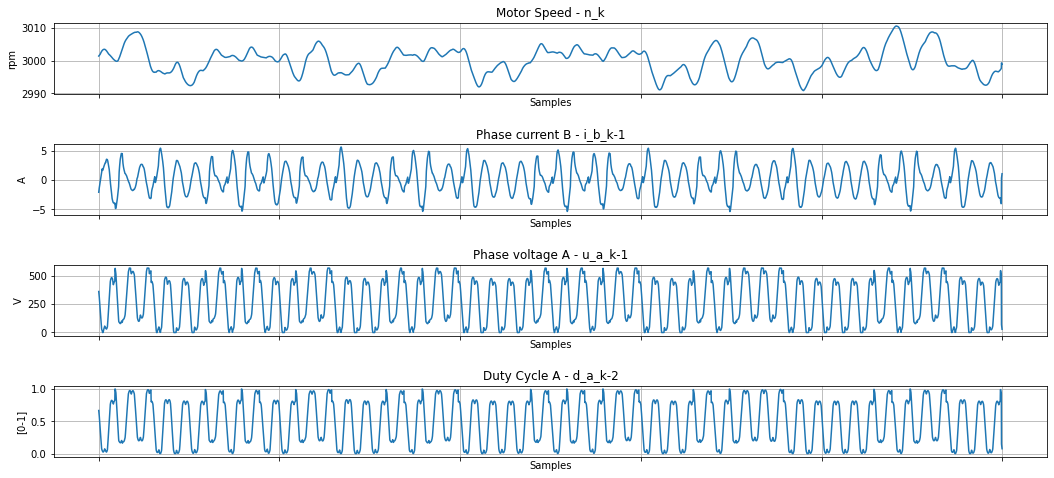

In [8]:
p_sample= 5000

col_iak1=data_raw['n_k'].head(p_sample)
p_iak1 = plt.subplot(4,1,1)
col_iak1.plot(use_index = True, figsize = (15,7))
plt.setp(p_iak1.get_xticklabels(), visible=False)
plt.title('Motor Speed - n_k')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('rpm')

col_iak1=data_raw['i_b_k-1'].head(p_sample)
p_iak1 = plt.subplot(4,1,2)
col_iak1.plot(use_index = True, figsize = (15,7))
plt.setp(p_iak1.get_xticklabels(), visible=False)
plt.title('Phase current B - i_b_k-1')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('A')

col_iak1=data_raw['u_a_k-1'].head(p_sample)
p_iak1 = plt.subplot(4,1,3)
col_iak1.plot(use_index = True, figsize = (15,7))
plt.setp(p_iak1.get_xticklabels(), visible=False)
plt.title('Phase voltage A - u_a_k-1')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('V')

col_iak1=data_raw['d_a_k-2'].head(p_sample)
p_iak1 = plt.subplot(4,1,4)
col_iak1.plot(use_index = True, figsize = (15,7))
plt.setp(p_iak1.get_xticklabels(), visible=False)
plt.title('Duty Cycle A - d_a_k-2')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('[0-1]')

plt.tight_layout(pad=2.0)



In [9]:
#correlation matrix
data_raw.corr()

,n_k,u_dc_k,u_dc_k-1,u_dc_k-2,u_dc_k-3,i_a_k,i_b_k,i_c_k,i_a_k-1,i_b_k-1,...,i_c_k-3,d_a_k-2,d_b_k-2,d_c_k-2,d_a_k-3,d_b_k-3,d_c_k-3,u_a_k-1,u_b_k-1,u_c_k-1
n_k,1.000000,-0.428551,-0.428544,-0.428539,-0.428535,0.000976,0.004075,0.003156,0.000992,0.004068,...,0.003129,0.000401,0.002339,0.002103,0.000409,0.002361,0.002084,-0.012105,-0.010189,-0.010992
u_dc_k,-0.428551,1.000000,0.997913,0.995965,0.993376,-0.006246,-0.002922,0.001044,-0.006376,-0.002761,...,0.001014,-0.004242,-0.007184,-0.006002,-0.004491,-0.007542,-0.006160,0.020417,0.017191,0.019000
u_dc_k-1,-0.428544,0.997913,1.000000,0.997913,0.995965,-0.006257,-0.002985,0.001125,-0.006325,-0.002871,...,0.001044,-0.004099,-0.006936,-0.005845,-0.004279,-0.007226,-0.005933,0.020601,0.017474,0.019218
u_dc_k-2,-0.428539,0.995965,0.997913,1.000000,0.997913,-0.006239,-0.003082,0.001196,-0.006334,-0.002937,...,0.001087,-0.004000,-0.006716,-0.005720,-0.004135,-0.006979,-0.005777,0.020713,0.017721,0.019377
u_dc_k-3,-0.428535,0.993376,0.995965,0.997913,1.000000,-0.006220,-0.003179,0.001260,-0.006322,-0.003034,...,0.001124,-0.003913,-0.006529,-0.005625,-0.004039,-0.006762,-0.005647,0.020793,0.017902,0.019476
i_a_k,0.000976,-0.006246,-0.006257,-0.006239,-0.006220,1.000000,-0.481779,-0.524303,0.998620,-0.517190,...,-0.413571,0.465385,0.327131,-0.785642,0.500605,0.287640,-0.783464,0.375554,0.395191,-0.763603
i_b_k,0.004075,-0.002922,-0.002985,-0.003082,-0.003179,-0.481779,1.000000,-0.493433,-0.444973,0.998566,...,-0.594599,-0.796127,0.487990,0.328403,-0.792778,0.523621,0.288071,-0.776911,0.398484,0.395154
i_c_k,0.003156,0.001044,0.001125,0.001196,0.001260,-0.524303,-0.493433,1.000000,-0.558727,-0.456837,...,0.988167,0.311639,-0.800406,0.462645,0.273236,-0.795780,0.499664,0.381857,-0.781295,0.375726
i_a_k-1,0.000992,-0.006376,-0.006325,-0.006334,-0.006322,0.998620,-0.444973,-0.558727,1.000000,-0.481756,...,-0.451505,0.428608,0.365535,-0.785042,0.465333,0.327124,-0.785621,0.337213,0.431479,-0.759405
i_b_k-1,0.004068,-0.002761,-0.002871,-0.002937,-0.003034,-0.517190,0.998566,-0.456837,-0.481756,1.000000,...,-0.562438,-0.796770,0.450686,0.367540,-0.796138,0.488020,0.328405,-0.773716,0.359517,0.432227


A correlation map has been created in order to evaluate the correlation between the different predictors and highlight the ones with highest relevance. 
We initially worked on building the training/test sets by using the whole predictors data and subsequently removing the predictors with lower correlation, measuring the difference in terms of accuracy.

The map shows the followings:
1. The motor speed (n_k) is correlated with dc voltages only (u_dc) and viceversa;
2. Almost no correlation is found between motor speed and dc voltages with phase currents (a,b,c) and phase voltages (a,b,c);
3. Phase currents (a,b,c) are correlated with duty cycles


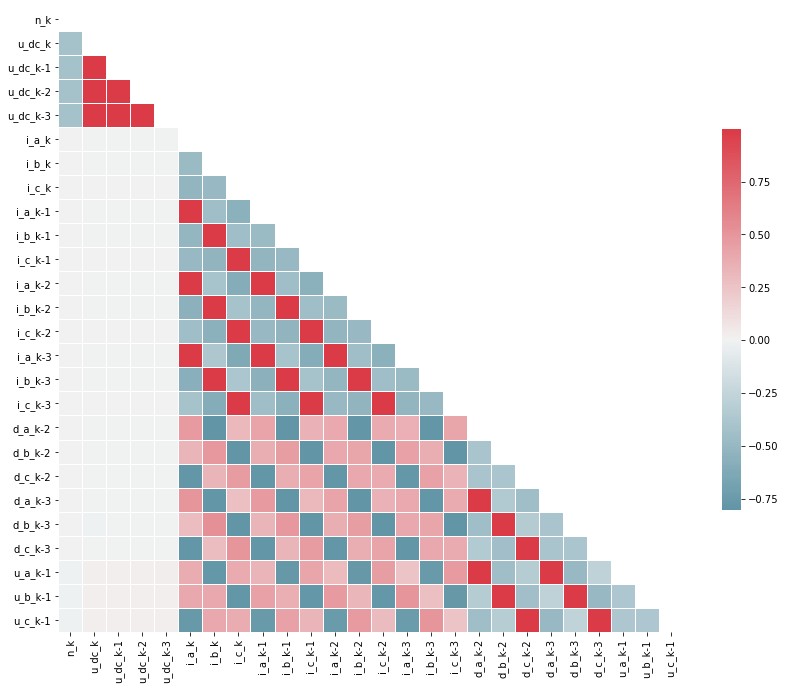

In [10]:
#correlation map
corr=data_raw.corr()

# Generate a mask for the upper triangle
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
# Generate a custom diverging colormap
cmap = sns.diverging_palette(220, 10, as_cmap=True)

plt.figure(figsize=(14,14))
_ = sns.heatmap(corr, mask=mask, cmap=cmap, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})



With the following plot we can visualize the correlation. The most correlated variables show variables close to the bisector while uncorrelated variables show chaotic patterns.


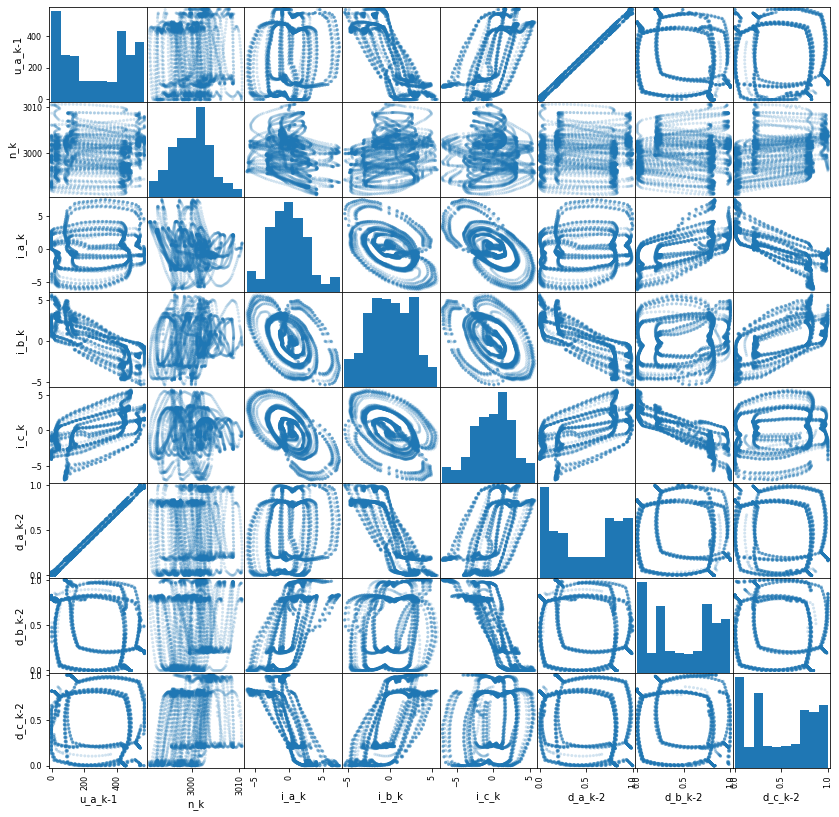

In [11]:

p_5 = data_raw[['u_a_k-1','n_k','i_a_k','i_b_k',
                'i_c_k','d_a_k-2','d_b_k-2','d_c_k-2']].head(5000)
pd.plotting.scatter_matrix(p_5, alpha=0.2, figsize=(14,14));


In [12]:
# Data Cutting
dfx1 = data_raw[['n_k','u_dc_k','u_dc_k-1','u_dc_k-2','u_dc_k-3','i_a_k','i_a_k-1',
                 'i_a_k-2','i_a_k-3','i_b_k','i_b_k-1','i_b_k-2','i_b_k-3','i_c_k',
                 'i_c_k-1','i_c_k-2','i_c_k-3','d_a_k-2','d_a_k-3','d_b_k-2','d_b_k-3',
                 'd_c_k-2','d_c_k-3']]

dfy1 = data_raw['u_a_k-1']   # phase A only: phases B and C are symmetric

# development / test split by blocks of 1000 consecutive samples
groups = np.arange(len(dfx1)) // 1000
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
dev_idx, test_idx = next(gss.split(dfx1, dfy1, groups))
X_dev, X_test = dfx1.iloc[dev_idx], dfx1.iloc[test_idx]
y_dev, y_test = dfy1.iloc[dev_idx], dfy1.iloc[test_idx]
g_dev = groups[dev_idx]
cv = GroupKFold(n_splits=5)                    # blocked 5-fold, development data only

# DEBUG = True keeps one development sample out of 5: use it for quick checks while editing
DEBUG = False
if DEBUG:
    X_dev, y_dev, g_dev = X_dev.iloc[::5], y_dev.iloc[::5], g_dev[::5]
print('development samples:', len(X_dev), '- test samples:', len(X_test))

development samples: 187527 - test samples: 47000


## Saving the results

Training every model takes a while, so the result of each step is saved in `/kaggle/working/cache`
(or `cache/` when the notebook runs on a local PC). When the notebook runs again, a step whose result
is already saved is loaded instead of recomputed.

To reuse the results of a previous version in a new Kaggle session, add that version's output as input
data (*Add Input → Your Work → this notebook*): the saved files are found anywhere under `/kaggle/input`
and copied to the new output. To recompute a step, put its name in `RECOMPUTE`.

Only results are saved (cross-validation tables and test-set predictions), not the fitted models,
which for the random forest would take several GB.

In [13]:
# results cache: compute once, then load from disk
CACHE_DIR = '/kaggle/working/cache' if os.path.isdir('/kaggle/working') else 'cache'
os.makedirs(CACHE_DIR, exist_ok=True)
RECOMPUTE = []          # names of the steps to recompute, e.g. ['rf']
N_JOBS = -1             # parallel jobs for scikit-learn; on a 16 GB laptop use 6

def cached(name, compute):
    """Return the saved result `name` if it exists, otherwise compute() it and save it."""
    if DEBUG:
        name += '_debug'
    file = name + '.joblib'
    here = os.path.join(CACHE_DIR, file)
    if name not in RECOMPUTE:
        for path in [here] + glob.glob('/kaggle/input/**/cache/' + file, recursive=True):
            if os.path.exists(path):
                if path != here:
                    shutil.copy(path, here)    # keep it in the output of this version too
                print('loaded', name, 'from', path)
                return joblib.load(here)
    result = compute()
    joblib.dump(result, here)
    return result

def search(name, model, grid, train_score=True):
    """5-fold blocked cross-validation on the development data, for every value in grid."""
    def compute():
        s = GridSearchCV(model, grid, cv=cv, n_jobs=N_JOBS, refit='mae',
                         scoring={'mae': 'neg_mean_absolute_error', 'mse': 'neg_mean_squared_error'},
                         return_train_score=train_score)
        s.fit(X_dev, y_dev, groups=g_dev)
        best = s.best_estimator_                   # already retrained on all the development data
        return {'cv_results': s.cv_results_, 'best_params': s.best_params_,
                'cv_mae': -s.best_score_, 'y_pred_test': best.predict(X_test),
                'n_nodes': best.tree_.node_count if hasattr(best, 'tree_') else None}
    r = cached(name, compute)
    print(name, r['best_params'], '- CV MAE = %.2f V' % r['cv_mae'])
    return r

def plot_cv(r, param, metric, title=''):
    """Training and validation error for every value tried by search()."""
    res = r['cv_results']
    x = [str(p[param]) for p in res['params']]
    plt.figure(figsize=(8,6))
    if 'mean_train_' + metric in res:              # kNN has no training error
        plt.plot(x, -res['mean_train_' + metric], 'o-', label='Training')
    plt.plot(x, -res['mean_test_' + metric], 'o-', label='Validation')
    plt.xlabel(param)
    plt.ylabel({'mae': 'MAE [V]', 'mse': 'MSE [V²]'}[metric])
    plt.title(title); plt.grid(); plt.legend()


# Data standardization
In order to have all the input variables on the same scale we perform standardization. This is fundamental for algorithms that use weights for assuring that each variable contributes equally.

In our case k-nearest neighbours and artificial neural network must use standardized input variables. Tree based algorithms (in our case decision tree, pruning and random forest) are insensitive to this problem since *they* classify based on punctual values and do not make any weighted operation.

In [14]:
scaler = StandardScaler()
dfx1_std = pd.DataFrame(scaler.fit_transform(dfx1)) 

The plot below is showing the motor speed before and after the standardization.

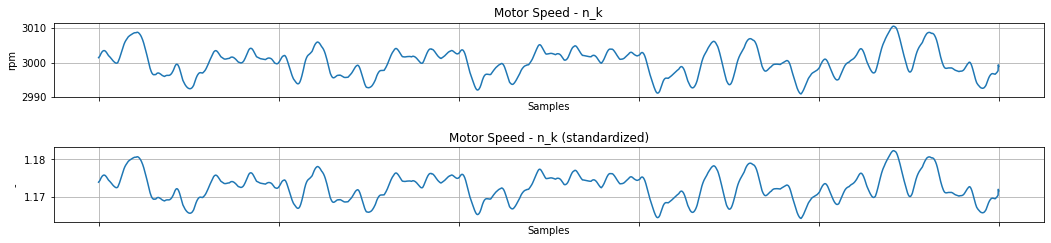

In [15]:
p_sample= 5000

col_iak1=data_raw['n_k'].head(p_sample)
p_iak1 = plt.subplot(4,1,1)
col_iak1.plot(use_index = True, figsize = (15,7))
plt.setp(p_iak1.get_xticklabels(), visible=False)
plt.title('Motor Speed - n_k')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('rpm')

col_iak1=dfx1_std[0].head(p_sample)
p_iak1 = plt.subplot(4,1,2)
col_iak1.plot(use_index = True, figsize = (15,7))
plt.setp(p_iak1.get_xticklabels(), visible=False)
plt.title('Motor Speed - n_k (standardized)')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('-')

plt.tight_layout(pad=2.0)

# Physical references

Before training the black-box models we define some simple references. The first is the ideal inverter, u = d·u_dc, with no parameters to fit. The second is a grey-box model: a linear regression on d·u_dc and on the sign of the phase current, which represents the voltage error due to dead time and to the voltage drop on the switches. The last one is a linear regression on all the 23 inputs.

The grey-box coefficients have a physical meaning: about 0.99 on d·u_dc, close to the ideal value of 1, and about -13 V on the sign of the current. The test errors of these models are in the final table.

In [16]:
phys = lambda X: X['d_a_k-2'] * X['u_dc_k-1']                 
F = lambda X: np.column_stack([phys(X), np.sign(X['i_a_k-1'])])
grey = LinearRegression().fit(F(X_dev), y_dev)                 
print('grey box coefficients:', grey.coef_, 'intercept:', grey.intercept_)
lin = Pipeline([('scaler', StandardScaler()), ('lin', LinearRegression())]).fit(X_dev, y_dev)

grey box coefficients: [  0.9927615  -13.03484059] intercept: 1.8487660706905444


# Score parameters used

MSE (Mean Square Error): it indicates the averaged squared difference between estimated data and observed data.

RMSE (Root Mean Square Error): it is the squared root of the mse.

MAE (Mean absolute error): it is the average of the difference between estimated and observed data.

R2 (coefficient of determination):  it is the ratio between the deviance of the predicted data and the one of the real data. The closer to 1 the more accurate is the model.

# K-Fold

K-fold method aims to randomly split our dataset into k folds of equal size, (k-1)/k data portion will be used for training while 1/k portion of data will be used for test.
This procedure is repeated k times changing the data portion, each time the model accuracy is computed and finally averaged.

K-fold is used to avoid dataset splitting dependence on model training accuracy. In this way we can have a reasonable result independently from the data partition in training and validation sets.

          first half    second half
count  117263.000000  117264.000000
mean     1785.163739    1671.666724
std      1254.468281     878.638712
min       404.433935     422.801987
25%       500.163775    1476.334128
50%      2971.264240    1501.154218
75%      3001.406793    2501.787864
max      3231.756077    3083.782210


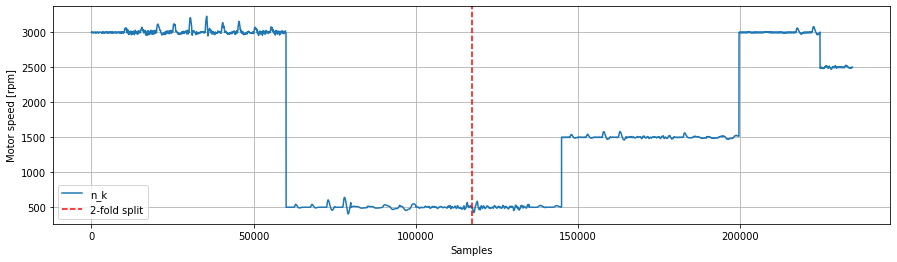

In [17]:
# check whether the two halves of the dataset cover different operating points
half = len(dfx1) // 2
print(pd.DataFrame({'first half': data_raw['n_k'].iloc[:half].describe(),
                    'second half': data_raw['n_k'].iloc[half:].describe()}))

plt.figure(figsize=(15,4))
data_raw['n_k'].plot()
plt.axvline(half, color='r', linestyle='--', label='2-fold split')
plt.xlabel('Samples'); plt.ylabel('Motor speed [rpm]'); plt.grid(); plt.legend()

In [18]:
model = DecisionTreeRegressor(max_depth=15, random_state=0)

# blocked 5-fold: validation blocks spread over the whole test campaign (interpolation)
s_block = cross_val_score(model, X_dev, y_dev, groups=g_dev, cv=cv,
                          scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
# contiguous 2-fold: train on one half, validate on the other half (extrapolation)
s_half = cross_val_score(model, X_dev, y_dev, cv=KFold(n_splits=2, shuffle=False),
                         scoring='neg_mean_absolute_error', n_jobs=N_JOBS)

print('blocked 5-fold     MAE = %.2f V' % -s_block.mean())
print('contiguous 2-fold  MAE = %.2f V' % -s_half.mean())

blocked 5-fold     MAE = 0.85 V
contiguous 2-fold  MAE = 12.53 V


# Cross-validation setup

Every model is evaluated with 5-fold cross-validation. The number of folds k is not a model hyperparameter: it only defines how the error is measured, while the final model is always trained on all the development data. A larger k gives each fold more training data (50 % of the data for k = 2, 80 % for k = 5, 95 % for k = 20), so the measured error naturally decreases as k grows. We therefore fix k = 5 a priori, a standard trade-off between the accuracy of the estimate and the computing time.

Each row contains the values of the three previous samples, so neighbouring rows are almost identical. Shuffling the rows at random would put near-duplicates in both training and validation and give an optimistic error, so the folds are built from blocks of 1000 consecutive samples (GroupKFold).

Hyperparameters are chosen on the development data only (80 % of the samples). The remaining 20 % is the test set, never used for training or for choosing the hyperparameters.

## Seen vs unseen operating points

The test bench ran the motor at a sequence of constant speeds (figure above): about 3000 rpm, then 500, 1500, 3000 and 2500 rpm. The first half of the dataset contains only the 3000 and 500 rpm steps, while 1500 and 2500 rpm appear only in the second half.

We measured this effect with a decision tree of depth 15. With blocked folds every speed is present in both training and validation, so the model only has to predict operating points it has already seen: MAE = 0.85 V. With two contiguous halves the error rises to 12.53 V (mean of the two folds), because in one of the folds the model must predict speeds it has never seen.

The black-box model is therefore reliable only at the operating points covered by its training data. Since the dataset contains only four constant speeds, its behaviour at other speeds and during speed transients is not validated.

# Decision Trees

Tree methods are simple methods that divide the predictor space in different areas depending on particular conditions that are found during the training phase.

The training depth, the number of levels of the tree, influences the model accuracy. If the number of levels is too high, the model will overfit, if it is too low, the model will have low accuracy.

In order to find the best trade-off between accuracy and overfitting, different values of tree depth have been used, the one with the lowest validation error has been finally selected.

Sensitivity analysis done varying max tree depth with:

*   5
*   10
*   15
*   20
*   25

In [19]:
dt = search('dt', DecisionTreeRegressor(random_state=0), {'max_depth': [5, 10, 15, 20, 25]})

dt {'max_depth': 20} - CV MAE = 0.80 V


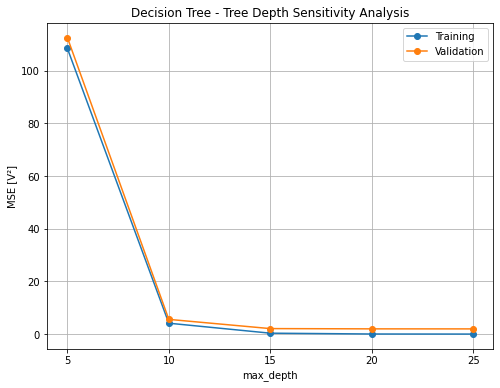

In [20]:
plot_cv(dt, 'max_depth', 'mse', 'Decision Tree - Tree Depth Sensitivity Analysis')

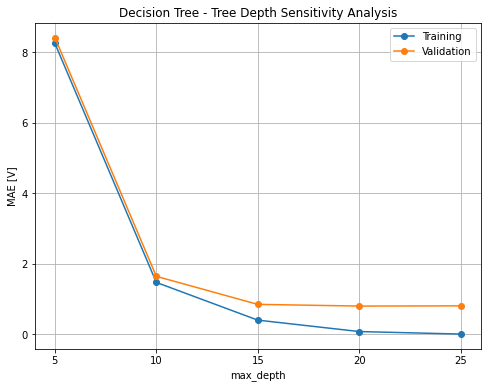

In [21]:
plot_cv(dt, 'max_depth', 'mae', 'Decision Tree - Tree Depth Sensitivity Analysis')

The lowest validation MAE is 0.80 V, with a depth of 20, well below the 2 V target. The error drops quickly up to depth 15 (0.85 V) and then it is almost flat, while the training error keeps falling towards zero: beyond this point the tree is only memorizing the training data.

In [22]:
#Best solution: the depth chosen by the cross-validation, retrained on all the development data
y_pred_test = dt['y_pred_test']

Text(0.5, 1.0, 'Decision Tree - Predicted')

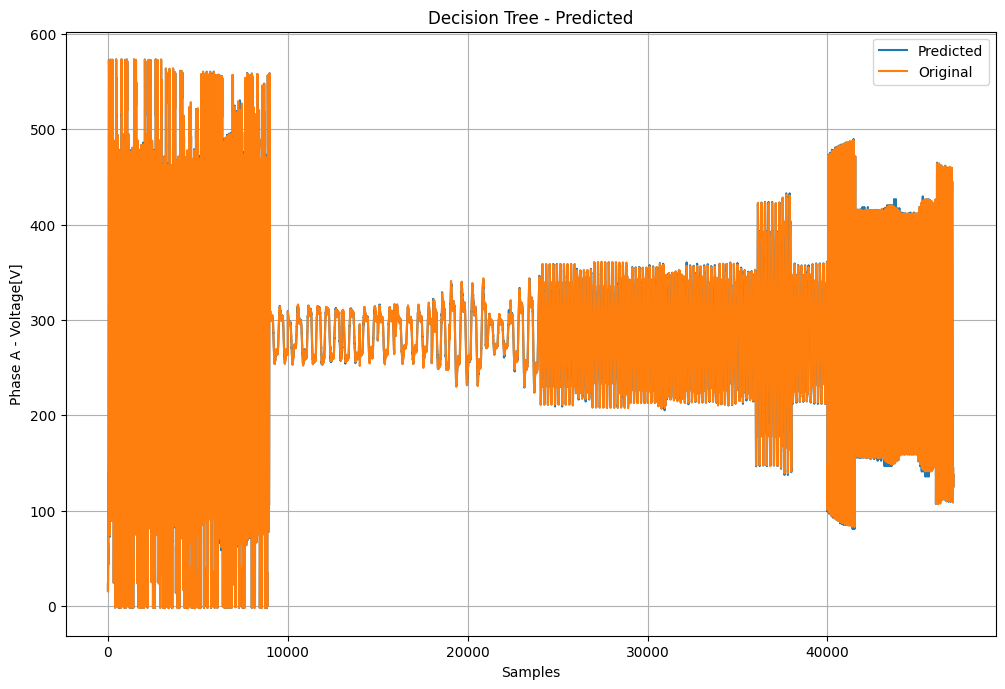

In [23]:
fig=plt.figure(figsize=(12,8), dpi= 100, facecolor='w', edgecolor='k')
a=np.arange(start=0, stop=len(y_pred_test), step=1)
plt.plot(a,y_pred_test,label='Predicted')
plt.plot(a,y_test,label='Original')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('Phase A - Voltage[V]')
plt.legend()
plt.title('Decision Tree - Predicted')


Text(0.5, 1.0, 'Decision Tree - Prediction Error')

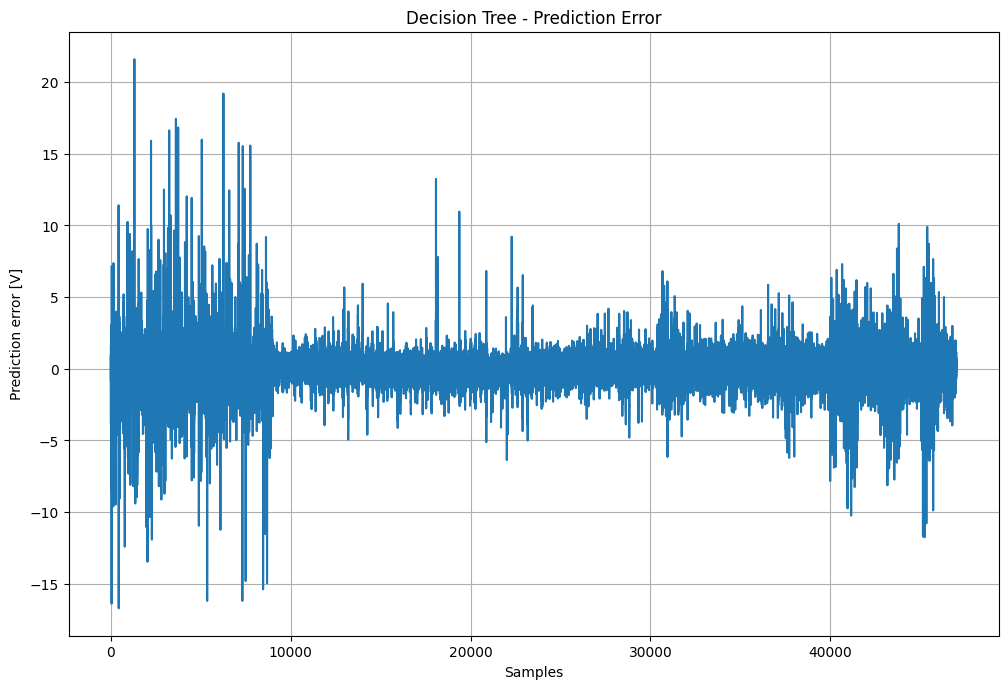

In [24]:
fig=plt.figure(figsize=(12,8), dpi= 100, facecolor='w', edgecolor='k')
a=np.arange(start=0, stop=len(y_pred_test), step=1)
plt.plot(a,y_pred_test-y_test)
plt.grid()
plt.xlabel('Samples')
plt.ylabel('Prediction error [V]')
plt.title('Decision Tree - Prediction Error')

Text(0.5, 1.0, 'Decision Tree - Predicted vs Measured')

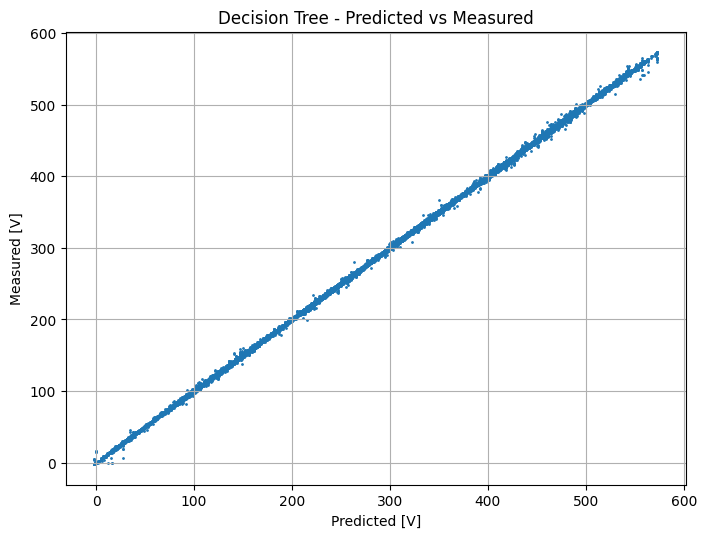

In [25]:
fig=plt.figure(figsize=(8,6), dpi= 100, facecolor='w', edgecolor='k')
plt.scatter(y_pred_test,y_test, s=1)
plt.grid()
plt.xlabel('Predicted [V]')
plt.ylabel('Measured [V]')
plt.title('Decision Tree - Predicted vs Measured')

The figures above show the best tree on the test set. The error is largest at 3000 rpm, with peaks of about 20 V, where the voltage swing is widest, and smallest at 500 rpm.

# Pruning

    
Decision tree methods may produce good predictions on the training
set, but they are likely to overfit the data, leading to poor test set performance.

This is because the resulting tree might be too complex. A smaller tree
with fewer splits might lead to lower variance. 
A better strategy is to grow a very large tree, and then prune it back in order to obtain a subtree. 

The subtrees set are found with the so called "cost complexity pruning": rather than considering every possible subtree, we consider a sequence of trees indexed by a nonnegative tuning parameter α.



The pruning parameter α is searched on a logarithmic grid (0, 0.001 … 100), pruning a fully grown tree,
with the same blocked 5-fold cross-validation.

In [26]:
alphas = [0, 1e-3, 1e-2, 1e-1, 1, 10, 100]
prn = search('pruning', DecisionTreeRegressor(random_state=0), {'ccp_alpha': alphas})
print('nodes of the best pruned tree:', prn['n_nodes'])

pruning {'ccp_alpha': 0} - CV MAE = 0.81 V
nodes of the best pruned tree: 374981


Text(0.5, 1.0, 'Pruning - Number of Nodes vs alpha')

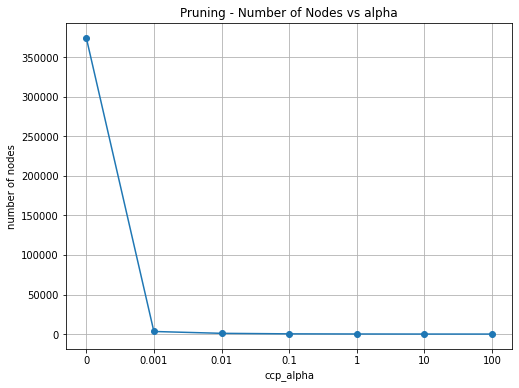

In [27]:
node_counts = cached('pruning_nodes', lambda: [
    DecisionTreeRegressor(random_state=0, ccp_alpha=a).fit(X_dev, y_dev).tree_.node_count for a in alphas])
plt.figure(figsize=(8,6))
plt.plot([str(a) for a in alphas], node_counts, 'o-')
plt.xlabel('ccp_alpha'); plt.ylabel('number of nodes'); plt.grid()
plt.title('Pruning - Number of Nodes vs alpha')

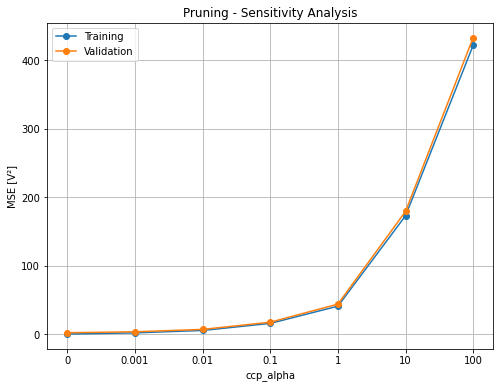

In [28]:
plot_cv(prn, 'ccp_alpha', 'mse', 'Pruning - Sensitivity Analysis')

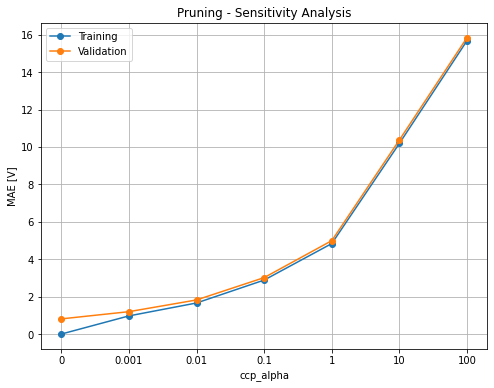

In [29]:
plot_cv(prn, 'ccp_alpha', 'mae', 'Pruning - Sensitivity Analysis')

## Pruning results

Pruning does not improve the error: the lowest validation MAE (0.81 V) is obtained with α = 0, the full tree with about 375,000 nodes. As α grows, training and validation errors rise together.

However pruning is very effective at reducing the size of the model. With α = 0.001 the tree keeps only a few thousand nodes (about 1 % of the full tree) and the validation MAE is still about 1.2 V, below the 2 V target. This could be useful for an embedded implementation.

# Random Forest

Decision trees have an intrinsic problem related to high variance. One of the most common method for avoiding it is the so called *bootstrap aggregation* or *bagging*, that is used to reduce the variance of a statistical learning method. This method is based on the fact that averaging a set of observations reduces the variance, thus we should find a way to have multiple data-set, to build a model for each of them and then to average the results. Since we do not always have multiple data-set we "artificially" create them with the bootstrapping technique.
However bagging method can create high correlated trees that are not very useful to reduce variance. An upgrade of bagging is the random forest method. The latter is very similar, it creates dataset by means of the bootstrapping technique but, when it creates a tree for each dataset, it considers for each split of the tree a subset of variables (usually sqrt(p), where p is the total number of variables).
This "reduction" allows to decorrelate the trees and, thus, to decrease the variance.  

In order to see the effect of the tree depth on the results, an array with different depths has been taken
[5,10,15,20,25]. The array is equal to the one used in the decision tree study. Each split considers
sqrt(23) ≈ 5 randomly chosen variables (`max_features='sqrt'`).

In [30]:
rf = search('rf', RandomForestRegressor(max_features='sqrt', random_state=0),
            {'max_depth': [5, 10, 15, 20, 25]})

rf {'max_depth': 25} - CV MAE = 1.16 V


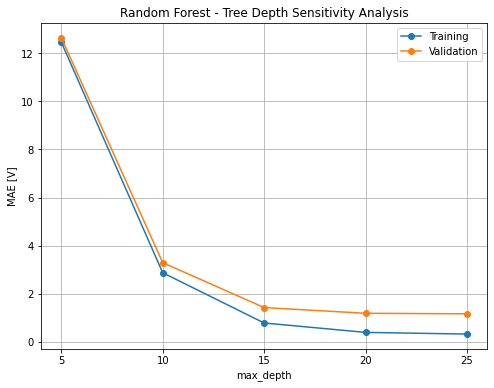

In [31]:
plot_cv(rf, 'max_depth', 'mae', 'Random Forest - Tree Depth Sensitivity Analysis')

The best result is 1.16 V with depth 25. It is below the 2 V target but worse than the single decision tree (0.80 V), with a much higher computing time (about 11 minutes against 1).

The likely reason is `max_features='sqrt'`: each split can choose among only 5 of the 23 variables, while the phase voltage depends mainly on a few of them (duty cycle and DC voltage), so many splits are made on weakly informative variables.

# kNN - k-nearest-neighbors

KNN regression is an algorithm that approximates the similarity between input variables and the continuous output by averaging the observations in the same neighbourhood.

Given some inputs  x0, the algorithm searches for the k nearest values present in the dataset (the most common way is computing the euclidean distance) and it then averages the related output values


The choice of k has a significant effect on the model performance, a low k can lead to low bias but high variance, viceversa an high k leads to high bias and low variance. 

In order to understand the effect of k on our model and to see which one fits better a sensitivity analysis has been performed.

In [32]:
knn = search('knn', Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())]),
             {'knn__n_neighbors': [3, 5, 15, 25, 51, 101]}, train_score=False)

knn {'knn__n_neighbors': 5} - CV MAE = 3.46 V


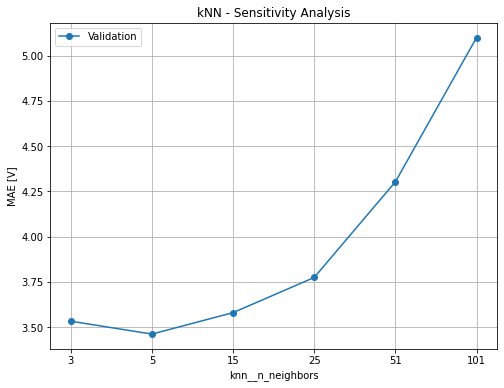

In [33]:
plot_cv(knn, 'knn__n_neighbors', 'mae', 'kNN - Sensitivity Analysis')

The values of k tried are [3, 5, 15, 25, 51, 101]; the training error is not computed for kNN, because predicting the whole training set is very slow.

The best result is obtained with k = 5, with a validation MAE of 3.46 V, and the error grows with k. This is above the 2 V target and much worse than the tree-based models. kNN gives the same weight to all the 23 standardized variables, while only a few of them really matter for the phase voltage, so it would not be employable for our purpose.

# ANN - Artificial Neural Network

Artificial Neural Networks are one of the main branches in the machine learning field. They are computational systems that try to replicate the structure of biological neural networks.
The main unit is the node (N), which communicates through links 
(L), with other nodes; the system is a dimensional space where N >> L. The nodes are organized in layers.

The basic structure includes:
• An input layer, which receives the inputs to be processed by the system;
• One or more intermediate layers (also called hidden);
• A final layer that provides the outputs.

The neuron is made up of three fundamental elements:
1. A variable number of connections characterized by weights;
2. An adder, which sums the inputs from the various connections based on their weight, producing as output a linear combination of the received inputs;
3. An activation function that serves to limit the value of the output. Usually the output is between the values ​​[0,1] or [-1,1].

There are several activation functions, the most used are the sigmoid and the ReLu (Rectified Linear Unit).

The neural network training can be done in two different ways: supervised (when the output as well as the input is known) and unsupervised(when only inputs are known).

The error signal activates a self-checking procedure of the system through a series of adjustments of the weight of each connection of the k-th neuron with the aim of reducing the difference between the response generated and the expected response.

In [34]:
def ann_predict(X_tr, y_tr, X_new, n_layers, n_neurons, n_pca=None):
    """Train a fully connected network on (X_tr, y_tr) and predict X_new.
    Standardization and PCA are fitted on the training data only."""
    scaler = StandardScaler().fit(X_tr)
    X_tr, X_new = scaler.transform(X_tr), scaler.transform(X_new)
    if n_pca:
        pca = PCA(n_components=n_pca).fit(X_tr)
        X_tr, X_new = pca.transform(X_tr), pca.transform(X_new)
    model = keras.Sequential(
        [keras.layers.Dense(n_neurons, activation='relu', input_shape=(X_tr.shape[1],))]
        + [keras.layers.Dense(n_neurons, activation='relu') for _ in range(n_layers - 1)]
        + [keras.layers.Dense(1)])
    model.compile(optimizer='adam', loss='mse')
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model.fit(X_tr, np.asarray(y_tr), epochs=150, batch_size=512,
              validation_split=0.1, callbacks=[es], verbose=0)
    return model.predict(X_new).ravel()

ANN_FOLDS = 1   # folds used to compare architectures: 1 = first fold only (fast), 5 = full cross-validation

def ann_cv(n_layers, n_neurons, n_pca=None):
    """Validation MAE of one architecture, averaged over the first ANN_FOLDS blocked folds."""
    splits = list(cv.split(X_dev, y_dev, g_dev))[:ANN_FOLDS]
    return np.mean([metrics.mean_absolute_error(
                        y_dev.iloc[va],
                        ann_predict(X_dev.iloc[tr], y_dev.iloc[tr], X_dev.iloc[va], n_layers, n_neurons, n_pca))
                    for tr, va in splits])

def ann_sweep(n_layers, neurons=(5, 10, 15, 20, 50)):
    """Validation MAE for every number of neurons, with n_layers hidden layers."""
    res = cached('ann_%dlayers_%dfold' % (n_layers, ANN_FOLDS),
                 lambda: {n: ann_cv(n_layers, n) for n in neurons})
    for n, m in res.items():
        print(n_layers, 'layers,', n, 'neurons - validation MAE = %.2f V' % m)
    return res

## 1 Layer Architecture
In order to understand which is the optimal number of neurons, we started using only one layer and we varied the number of neurons [5,10,15,20,50]. ReLu were used as activation functions in the hidden layer while linear function was used for the output layer (since output values are unbounded).
Each network is trained for at most 150 epochs, in batches of 512 samples, with early stopping on a 10 % validation split (training stops after 5 epochs without improvement and keeps the best weights).

In [35]:
ann1 = ann_sweep(1)

1 layers, 5 neurons - validation MAE = 4.18 V
1 layers, 10 neurons - validation MAE = 1.39 V
1 layers, 15 neurons - validation MAE = 1.69 V
1 layers, 20 neurons - validation MAE = 1.39 V
1 layers, 50 neurons - validation MAE = 1.39 V


With one hidden layer, 5 neurons are not enough (4.18 V). From 10 neurons on the validation MAE is between 1.4 and 1.7 V, and adding neurons does not help.

## 3 Hidden Layers
A further analysis with 3 layers has been done with the purpose of understanding if the errors could decrease.

In [36]:
ann3 = ann_sweep(3)

3 layers, 5 neurons - validation MAE = 5.16 V
3 layers, 10 neurons - validation MAE = 1.16 V
3 layers, 15 neurons - validation MAE = 1.36 V
3 layers, 20 neurons - validation MAE = 1.23 V
3 layers, 50 neurons - validation MAE = 1.39 V


With 3 hidden layers the best result is 1.16 V with 10 neurons, better than with 1 layer. Again 5 neurons are not enough (5.16 V).

## 5 Hidden Layers

The training has been repeated with 5 hidden layers, considering the same number of neurons.

In [37]:
ann5 = ann_sweep(5)

5 layers, 5 neurons - validation MAE = 4.71 V
5 layers, 10 neurons - validation MAE = 1.24 V
5 layers, 15 neurons - validation MAE = 1.17 V
5 layers, 20 neurons - validation MAE = 1.66 V
5 layers, 50 neurons - validation MAE = 1.17 V


best architecture: 3 layers x 10 neurons


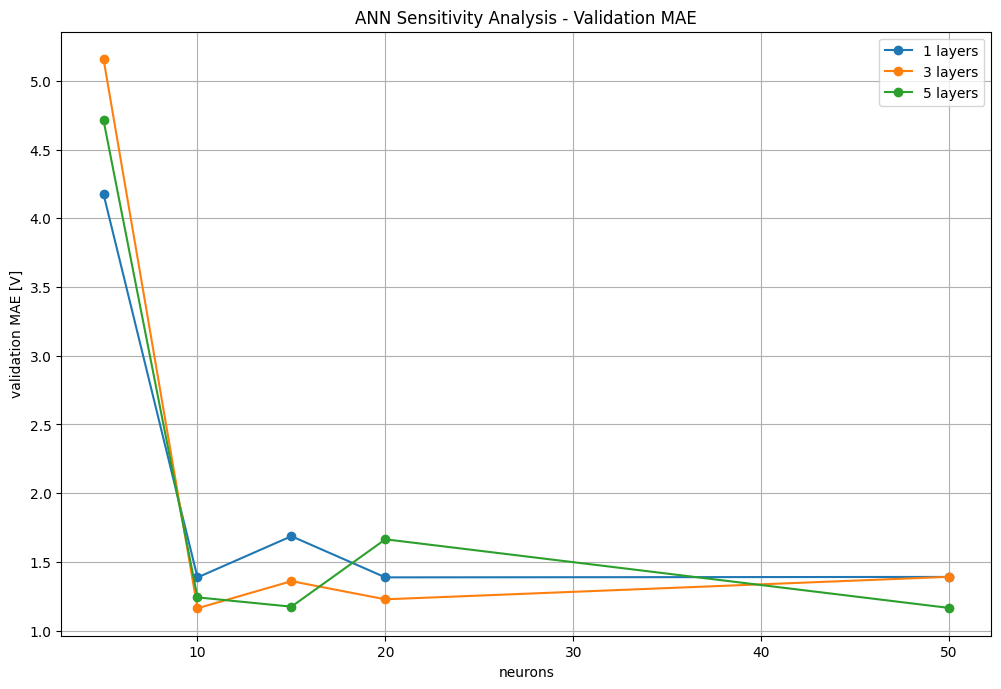

In [38]:
neuronsV = [5, 10, 15, 20, 50]
fig=plt.figure(figsize=(12,8), dpi= 100, facecolor='w', edgecolor='k')
for n_layers, res in [(1, ann1), (3, ann3), (5, ann5)]:
    plt.plot(neuronsV, [res[n] for n in neuronsV], '-o', label='%d layers' % n_layers)
plt.grid()
plt.xlabel('neurons')
plt.ylabel('validation MAE [V]')
plt.legend()
plt.title('ANN Sensitivity Analysis - Validation MAE')

cv_ann = {(l, n): m for l, res in [(1, ann1), (3, ann3), (5, ann5)] for n, m in res.items()}
best_layers, best_neurons = min(cv_ann, key=cv_ann.get)
print('best architecture:', best_layers, 'layers x', best_neurons, 'neurons')

5 hidden layers do not bring further improvements: the best value is 1.17 V, the same as with 3 layers. The curves are not smooth because, to save time, each architecture was trained only once and compared on a single fold, so differences of a few tenths of a volt are probably due to the random initialization of the weights. The clear result is that at least 10 neurons are needed.

The architecture with the lowest validation MAE (3 layers of 10 neurons) is retrained on all the development data and evaluated on the test set.

In [39]:
ann_pred_test = cached('ann_test_%dx%d' % (best_layers, best_neurons),
                       lambda: ann_predict(X_dev, y_dev, X_test, best_layers, best_neurons))
y_pred_test = ann_pred_test

Text(0.5, 1.0, 'Neural Network - Predicted Values')

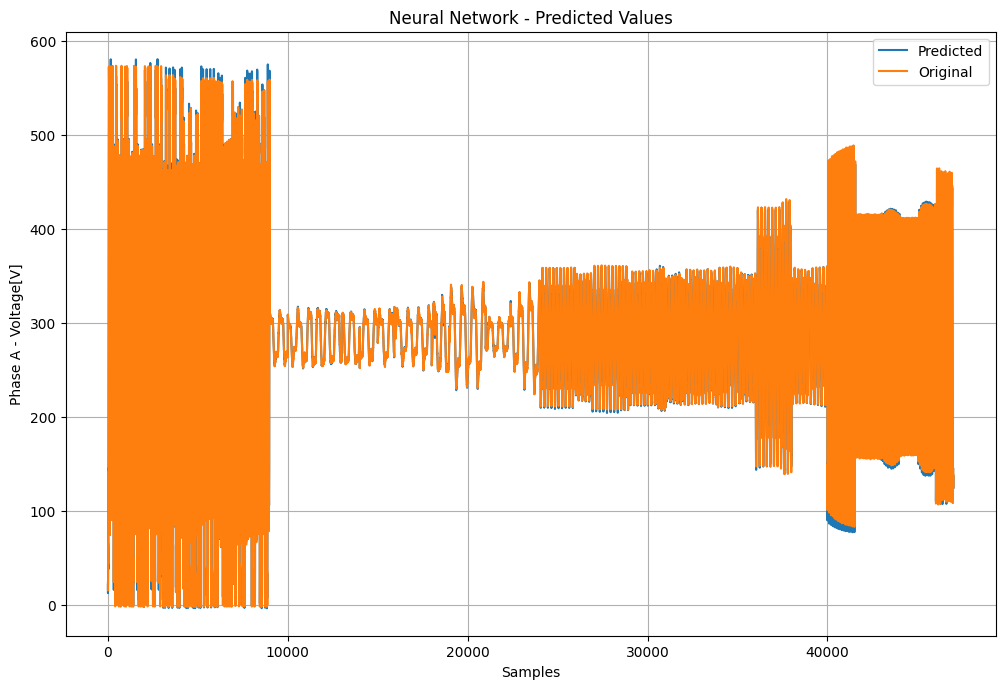

In [40]:
fig=plt.figure(figsize=(12,8), dpi= 100, facecolor='w', edgecolor='k')
a=np.arange(start=0, stop=len(y_pred_test), step=1)
plt.plot(a,y_pred_test,label='Predicted')
plt.plot(a,y_test,label='Original')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('Phase A - Voltage[V]')
plt.legend()
plt.title('Neural Network - Predicted Values')

The network follows the measured voltage well, with a test MAE of 1.12 V and only 471 weights. We then repeated the training applying PCA in order to see the effects of a reduced dataset.

# PCA - Principal Component Analysis

The principal component analysis is a linear algebra technique that allows to create a subset of the original dataset without losing most of the information.
This method is very useful when we are dealing with large dataset that contains redundant variables since it creates a smaller and more usable dataset. The drawback of this method is that we lose the meaning of the variables.

In order to perform the PCA we have to standardize our dataset, then we have to compute the covariance matrix. Computing the eigenvectors of this matrix and sorting them from the highest eigenvalue. The corresponding eigenvectors will be our components. Then we can project our original dataset on each subset of components in order to evaluate the quality of our projection on each subset: the more the components the more similar the subset will be to the original one.
However we can see that a smaller number of components can lead to a dataset that has an explained variance very similar to the original one.

In our case we have 23 components (since we have 23 input variables) and it is sufficient to select the first 6 components in order to have 98% of the explained variance.

[ 35.65429973  70.73612307  89.23879159  92.43544752  95.40615269
  98.11984409  99.90493278  99.93585414  99.95401674  99.96980286
  99.98094405  99.9879062   99.99315532  99.99545941  99.99764665
  99.99852343  99.99900764  99.99945558  99.99967751  99.99978871
  99.99987409  99.99995532 100.        ]


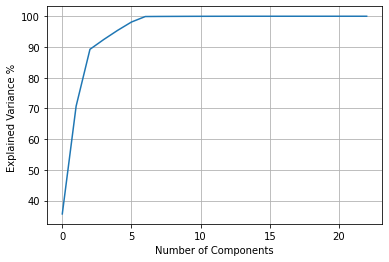

In [41]:
pca23 = PCA(n_components=23).fit(StandardScaler().fit_transform(X_dev))   # development data only
print(np.cumsum(pca23.explained_variance_ratio_)*100)
plt.plot(np.cumsum(pca23.explained_variance_ratio_)*100)
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance % ')
plt.grid()

In [42]:
mae_pca6 = cached('ann_pca6_%dx%d_%dfold' % (best_layers, best_neurons, ANN_FOLDS),
                  lambda: ann_cv(best_layers, best_neurons, n_pca=6))
print('PCA 6 components - validation MAE = %.2f V' % mae_pca6)

PCA 6 components - validation MAE = 12.47 V


With 6 components the validation MAE is 12.47 V, much worse than the 1.16 V obtained with all the inputs, even though these components keep 98 % of the variance. For this reason we also tried 10 components.

In [43]:
mae_pca10 = cached('ann_pca10_%dx%d_%dfold' % (best_layers, best_neurons, ANN_FOLDS),
                   lambda: ann_cv(best_layers, best_neurons, n_pca=10))
print('PCA 10 components - validation MAE = %.2f V' % mae_pca10)

PCA 10 components - validation MAE = 3.43 V


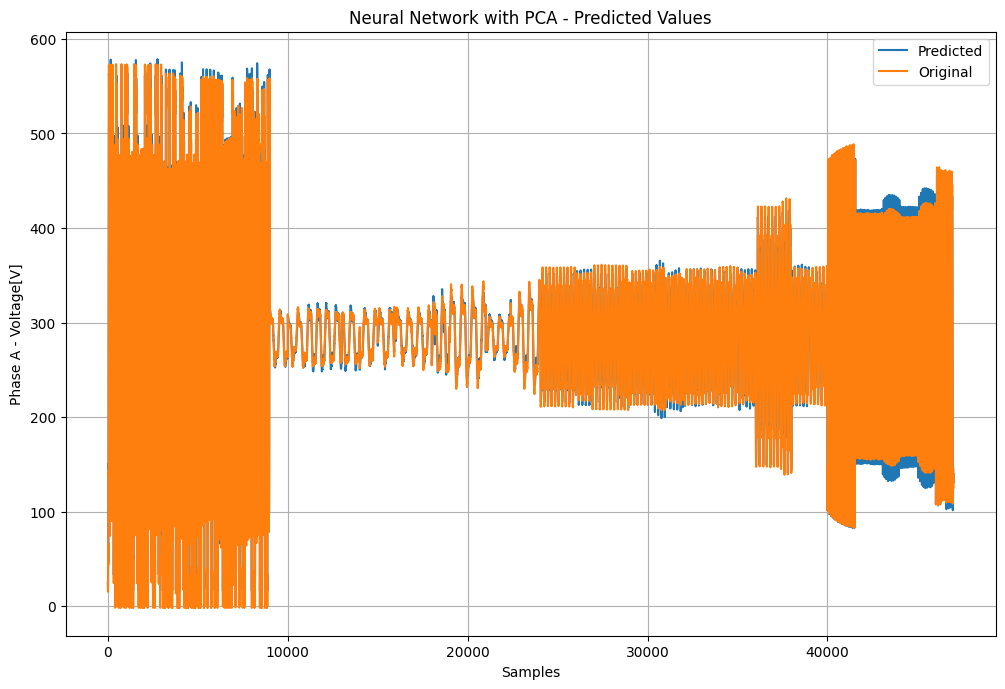

In [44]:
pca_pred_test = cached('ann_pca10_test_%dx%d' % (best_layers, best_neurons),
                       lambda: ann_predict(X_dev, y_dev, X_test, best_layers, best_neurons, n_pca=10))
y_pred_test = pca_pred_test

stfig=plt.figure(figsize=(12,8), dpi= 100, facecolor='w', edgecolor='k')
a=np.arange(start=0, stop=len(y_pred_test), step=1)
plt.plot(a,y_pred_test,label='Predicted')
plt.plot(a,y_test,label='Original')
plt.grid()
plt.xlabel('Samples')
plt.ylabel('Phase A - Voltage[V]')
plt.legend()
plt.title('Neural Network with PCA - Predicted Values');

With 10 components the validation MAE falls to 3.43 V, but the test MAE (4.29 V) is still above the 2 V target and almost four times the error of the same network without PCA (1.12 V).

PCA is therefore not useful here. It keeps the directions with the largest input variance, which are not necessarily the ones that matter for the target: each input is strongly correlated with its previous samples, and the small differences between them are probably what the network needs.

# Final comparison on the test set

All the models are compared on the test set: 20 % of the data, in blocks of 1000 samples, never used for
training or for choosing the hyperparameters.

In [45]:
mae = metrics.mean_absolute_error
results = {
    'Physics (d * u_dc)':  mae(y_test, phys(X_test)),
    'Grey box':            mae(y_test, grey.predict(F(X_test))),
    'Linear regression':   mae(y_test, lin.predict(X_test)),
    'Decision tree':       mae(y_test, dt['y_pred_test']),
    'Pruned tree':         mae(y_test, prn['y_pred_test']),
    'Random forest':       mae(y_test, rf['y_pred_test']),
    'kNN':                 mae(y_test, knn['y_pred_test']),
    'ANN %dx%d' % (best_layers, best_neurons):        mae(y_test, ann_pred_test),
    'ANN %dx%d + PCA 10' % (best_layers, best_neurons): mae(y_test, pca_pred_test),
}
pd.Series(results).round(2).to_frame('Test MAE [V]')

,Test MAE [V]
Physics (d * u_dc),13.46
Grey box,2.97
Linear regression,4.69
Decision tree,0.72
Pruned tree,0.73
Random forest,1.10
kNN,2.86
ANN 3x10,1.12
ANN 3x10 + PCA 10,4.29


# Conclusions

- **Physical references:** the ideal inverter has an error of 13.46 V. Adding only the sign of the current (grey box) brings it down to 2.97 V, better than a linear regression on all the 23 inputs (4.69 V).
- **Black-box models:** the decision tree (0.72 V), the random forest (1.10 V) and the neural network (1.12 V) meet the 2 V target, while kNN (2.86 V) and the network with PCA (4.29 V) do not. The "pruned tree" of the table has α = 0, so it is the full tree.
- **Best model:** the decision tree has the lowest error, but the full tree has about 375,000 nodes, while the network has only 471 weights. For an implementation on an inverter control unit, the network or a strongly pruned tree would be a better compromise.
- **Limits:** the test samples come from the same four constant speeds used for training. With unseen operating points the error of the tree reaches 12.53 V, so these results are valid only at the tested operating points. More speeds and transients would be needed before using the model on a real system.